# Fase 6 - Entrega 1: Visão Computacional com YOLO

**FarmTech Solutions** - demonstração de um sistema de detecção de objetos

## 1. Introdução

A FarmTech Solutions expandiu seus serviços de IA para além do agronegócio e passou a atuar com visão computacional. Este trabalho apresenta um sistema de detecção de objetos baseado no **YOLOv5**, treinado com um conjunto de imagens próprio, com o objetivo de demonstrar a um cliente o funcionamento prático dessa tecnologia.

### Cenário

Foram escolhidos dois objetos do ambiente rural, visualmente bem diferentes entre si:

- **Objeto A: vaca** - ser vivo, com formas arredondadas e grande variação de cor e pelagem
- **Objeto B: trator** - máquina, com formato rígido, rodas grandes e cores fortes

A diferença entre as duas classes permite avaliar se o modelo consegue localizar e separar corretamente cada objeto.

### Dataset

| Etapa | Imagens por objeto | Total |
|---|---|---|
| Treino | 32 | 64 |
| Validação | 4 | 8 |
| Teste | 4 | 8 |
| **Total** | **40** | **80** |

As imagens foram obtidas no Wikimedia Commons, somente com licenças livres (CC BY, CC BY-SA e domínio público). A origem, o autor e a licença de cada imagem estão no arquivo `CREDITOS.csv`.

### Etapas do notebook

1. Conexão com o Google Drive e conferência do dataset
2. Organização dos dados no formato exigido pelo YOLOv5
3. Treinamento com **30** e **60 épocas**
4. Validação e comparação das métricas
5. Teste em imagens não utilizadas no treinamento
6. Conclusões

## 2. Preparação do ambiente

O notebook deve ser executado no Google Colab com GPU (*Ambiente de execução > Alterar tipo de ambiente de execução > GPU*). Sem GPU, o treinamento fica significativamente mais lento.

In [1]:
# bibliotecas utilizadas
import os
import glob
import shutil
import time

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
# montagem do Google Drive no Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# pasta do projeto no Drive e classes (0 = vaca, 1 = trator)
BASE = '/content/drive/MyDrive/FIAP/FASE6_CAP1'
CLASSES = ['vaca', 'trator']

print('Pasta existe?', os.path.exists(BASE))
print('Conteudo:', os.listdir(BASE))

Pasta existe? True
Conteudo: ['rotulos', 'teste', 'treino', 'validacao']


## 3. Conferência do dataset

Contagem das imagens de cada pasta para confirmar a divisão de 32 imagens para treino, 4 para validação e 4 para teste em cada classe.

In [4]:
# quantidade de imagens por etapa e classe
for etapa in ['treino', 'validacao', 'teste']:
    for classe in CLASSES:
        pasta = os.path.join(BASE, etapa, classe)
        qtd = len(glob.glob(os.path.join(pasta, '*.jpg')))
        print(f'{etapa}/{classe}: {qtd} imagens')

treino/vaca: 32 imagens
treino/trator: 32 imagens
validacao/vaca: 4 imagens
validacao/trator: 4 imagens
teste/vaca: 4 imagens
teste/trator: 4 imagens


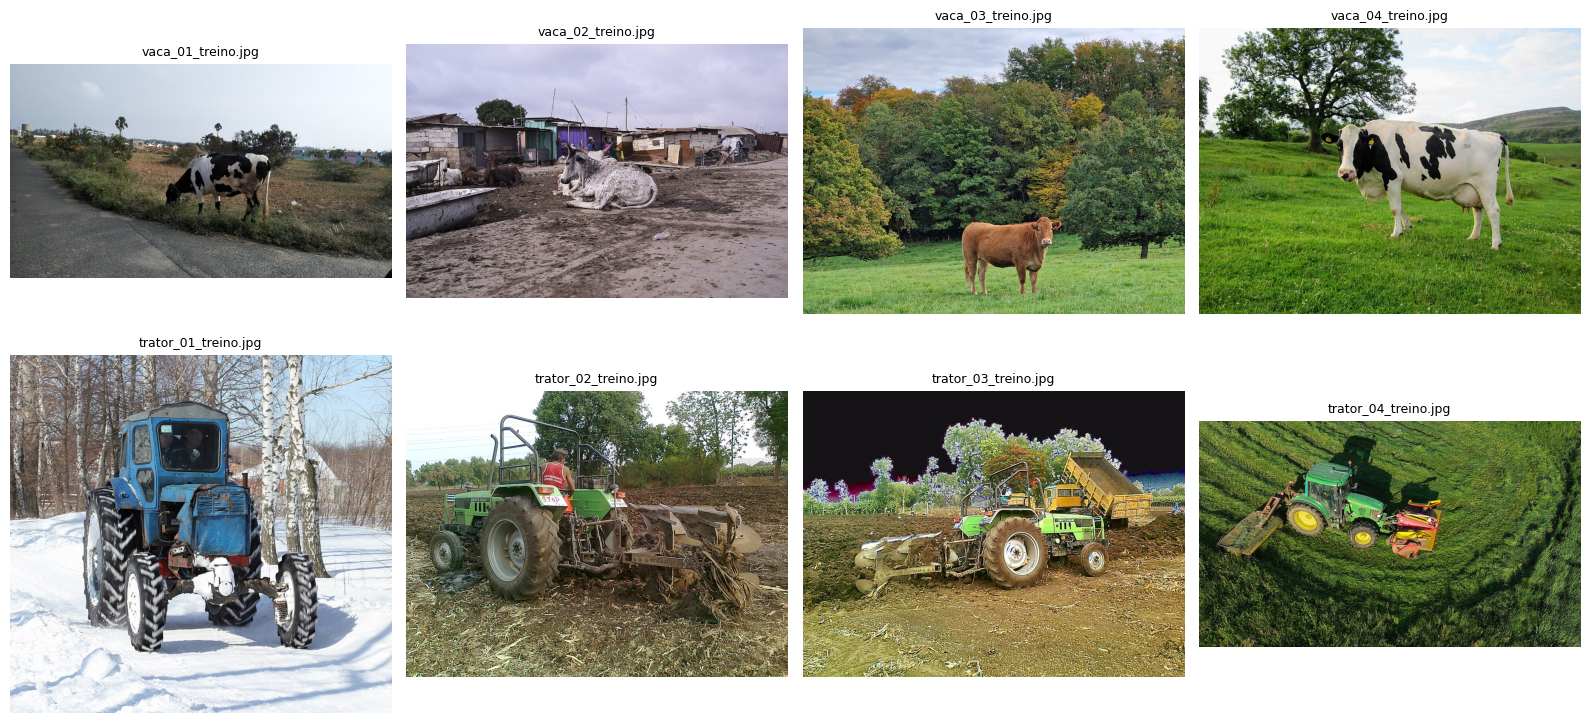

In [5]:
# amostra de 4 imagens de treino por classe
fig, eixos = plt.subplots(2, 4, figsize=(16, 8))

for i, classe in enumerate(CLASSES):
    arquivos = sorted(glob.glob(os.path.join(BASE, 'treino', classe, '*.jpg')))[:4]
    for j, arq in enumerate(arquivos):
        eixos[i][j].imshow(Image.open(arq))
        eixos[i][j].set_title(os.path.basename(arq), fontsize=9)
        eixos[i][j].axis('off')

plt.tight_layout()
plt.show()

## 4. Rotulação das imagens (Make Sense)

Para que o YOLO aprenda a localizar os objetos, cada imagem precisa indicar **onde** o objeto está. A rotulação foi feita manualmente no site [Make Sense](https://www.makesense.ai/), com uma caixa delimitadora em volta de cada vaca e de cada trator.

Procedimento adotado:

1. Acessar o Make Sense e clicar em *Get Started*
2. Carregar as imagens de **treino e validação** (as imagens de teste não precisam de rótulo, pois servem apenas para avaliar as detecções do modelo)
3. Selecionar a opção *Object Detection*
4. Criar os rótulos na ordem `vaca` e `trator`
5. Desenhar um retângulo em cada objeto e atribuir o rótulo correspondente
6. Exportar em *Actions > Export Annotations*, no formato **YOLO**
7. Extrair os arquivos `.txt` na pasta `rotulos` do Google Drive

Cada arquivo `.txt` tem o mesmo nome da imagem e uma linha por objeto, no formato:

`classe  x_centro  y_centro  largura  altura` (valores normalizados entre 0 e 1)

As imagens de validação também foram rotuladas, pois o YOLOv5 utiliza esses rótulos para calcular precisão, recall e mAP durante o treinamento. Ao todo foram rotuladas 72 imagens, com 46 caixas de vaca e 36 de trator (algumas imagens contêm mais de uma vaca).

In [6]:
# rotulos exportados do Make Sense
rotulos = glob.glob(os.path.join(BASE, 'rotulos', '**', '*.txt'), recursive=True)
print('Arquivos de rotulo encontrados:', len(rotulos))
print('Esperado: 72 (64 de treino + 8 de validacao)')

Arquivos de rotulo encontrados: 72
Esperado: 72 (64 de treino + 8 de validacao)


In [7]:
# exemplo de arquivo de rotulo
if rotulos:
    exemplo = sorted(rotulos)[0]
    print('Arquivo:', os.path.basename(exemplo))
    print(open(exemplo).read())

Arquivo: trator_01_treino.txt
1 0.496484 0.488025 0.689170 0.853238



## 5. Organização dos dados para o YOLOv5

O YOLOv5 exige uma estrutura de pastas específica, com imagens e rótulos separados em `train` e `val`. Essa estrutura é montada em uma pasta local do Colab (`/content/dataset`) a partir dos arquivos do Drive.

In [8]:
# estrutura local no formato do YOLOv5
DATASET = '/content/dataset'

# remove dados de execucoes anteriores
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

for parte in ['images/train', 'images/val', 'labels/train', 'labels/val', 'teste']:
    os.makedirs(os.path.join(DATASET, parte))

# nome da pasta no Drive -> nome usado pelo YOLO
mapa = {'treino': 'train', 'validacao': 'val'}

# rotulos indexados pelo nome do arquivo (sem extensao)
indice_rotulos = {os.path.splitext(os.path.basename(r))[0]: r for r in rotulos}

faltando = []

# copia imagens e rotulos de treino e validacao
for etapa, nome_yolo in mapa.items():
    for classe in CLASSES:
        for img in glob.glob(os.path.join(BASE, etapa, classe, '*.jpg')):
            nome = os.path.splitext(os.path.basename(img))[0]
            shutil.copy(img, os.path.join(DATASET, 'images', nome_yolo))
            if nome in indice_rotulos:
                shutil.copy(indice_rotulos[nome], os.path.join(DATASET, 'labels', nome_yolo, nome + '.txt'))
            else:
                faltando.append(nome)

# imagens de teste reunidas em uma unica pasta
for classe in CLASSES:
    for img in glob.glob(os.path.join(BASE, 'teste', classe, '*.jpg')):
        shutil.copy(img, os.path.join(DATASET, 'teste'))

print('Imagens de treino:', len(os.listdir(DATASET + '/images/train')))
print('Imagens de validacao:', len(os.listdir(DATASET + '/images/val')))
print('Imagens de teste:', len(os.listdir(DATASET + '/teste')))
print('Rotulos de treino:', len(os.listdir(DATASET + '/labels/train')))
print('Rotulos de validacao:', len(os.listdir(DATASET + '/labels/val')))
print('Imagens sem rotulo:', faltando)

Imagens de treino: 64
Imagens de validacao: 8
Imagens de teste: 8
Rotulos de treino: 64
Rotulos de validacao: 8
Imagens sem rotulo: []


In [9]:
# arquivo de configuracao do dataset lido pelo YOLOv5
conteudo_yaml = f'''path: {DATASET}
train: images/train
val: images/val

nc: {len(CLASSES)}
names: {CLASSES}
'''

with open('/content/dataset.yaml', 'w') as f:
    f.write(conteudo_yaml)

print(conteudo_yaml)

path: /content/dataset
train: images/train
val: images/val

nc: 2
names: ['vaca', 'trator']



## 6. Instalação do YOLOv5

Clonagem do repositório oficial do YOLOv5 e instalação das dependências.

In [10]:
# repositorio e dependencias do YOLOv5
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
!pip install -r requirements.txt -q

Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (341/341), done.
remote: Compressing objects: 100% (201/201), done.
remote: Total 18770 (delta 276), reused 140 (delta 140), pack-reused 18429 (from 5)
Receiving objects: 100% (18770/18770), 17.77 MiB | 17.96 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 9.4 MB/s eta 0:00:00


In [11]:
# verificacao da GPU
import torch
print('Versao do torch:', torch.__version__)
print('GPU disponivel?', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Placa:', torch.cuda.get_device_name(0))

Versao do torch: 2.11.0+cu130
GPU disponivel? True
Placa: Tesla T4


## 7. Treinamento

O modelo foi treinado **duas vezes**, alterando apenas o número de épocas:

- **Simulação 1:** 30 épocas
- **Simulação 2:** 60 épocas

Os demais parâmetros foram mantidos fixos: modelo `yolov5s` (a versão menor, já pré-treinada no dataset COCO), imagens redimensionadas para 640 pixels e batch de 8, adequado a um dataset pequeno.

Uma **época** corresponde a uma passagem completa do modelo por todas as imagens de treino. Mais épocas dão ao modelo mais oportunidades de aprendizado, mas aumentam o tempo de treinamento e o risco de *overfitting*, quando o modelo memoriza as imagens de treino e perde capacidade de generalizar. O tempo de cada treinamento também foi medido.

In [12]:
# simulacao 1: 30 epocas
inicio = time.time()

!python train.py --img 640 --batch 8 --epochs 30 --data /content/dataset.yaml --weights yolov5s.pt --name treino_30ep

tempo_30 = time.time() - inicio
print(f'Tempo do treino com 30 epocas: {tempo_30/60:.1f} minutos')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791914288.123815    2641 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/dataset.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=8, imgsz=640, rect

In [13]:
# simulacao 2: 60 epocas
inicio = time.time()

!python train.py --img 640 --batch 8 --epochs 60 --data /content/dataset.yaml --weights yolov5s.pt --name treino_60ep

tempo_60 = time.time() - inicio
print(f'Tempo do treino com 60 epocas: {tempo_60/60:.1f} minutos')

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791914450.793782    3489 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/dataset.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train

## 8. Validação

A validação mede o desempenho do modelo nas 8 imagens que **não são usadas para ajustar os pesos**. As métricas analisadas são:

- **Precisão:** proporção das caixas previstas que estavam corretas
- **Recall:** proporção dos objetos existentes que foram encontrados
- **mAP@0.5:** precisão média, considerando correta a caixa que cobre pelo menos 50% do objeto real
- **mAP@0.5:0.95:** mesma ideia, mas exigindo sobreposições cada vez maiores (métrica mais rigorosa)
- **Erro (loss):** quanto menor, melhor o ajuste do modelo

A tabela abaixo usa os valores da **última época** de cada treino. Em seguida, o `val.py` avalia os **melhores pesos** (`best.pt`) e mostra as métricas separadas por classe.

In [14]:
# resultados por epoca de cada treino
res30 = pd.read_csv('runs/train/treino_30ep/results.csv')
res60 = pd.read_csv('runs/train/treino_60ep/results.csv')

# remove espacos dos nomes das colunas
res30.columns = res30.columns.str.strip()
res60.columns = res60.columns.str.strip()

res60.head()

,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
0,0,0.099508,0.032610,0.025956,0.002098,0.51786,0.004426,0.001614,0.120760,0.025589,0.025879,0.093700,0.000700,0.000700
1,1,0.084971,0.030022,0.020012,0.002927,0.71429,0.016752,0.004741,0.116390,0.023994,0.025140,0.086475,0.001475,0.001475
2,2,0.082075,0.030084,0.020139,0.003337,0.78571,0.038739,0.016028,0.110090,0.022217,0.023065,0.079224,0.002224,0.002224
3,3,0.090446,0.032510,0.021973,0.003743,0.85714,0.134010,0.069806,0.101830,0.020514,0.018982,0.071947,0.002946,0.002946
4,4,0.072693,0.032899,0.016709,0.003751,0.85714,0.242410,0.089250,0.095083,0.020334,0.017905,0.064643,0.003643,0.003643


In [15]:
# comparacao entre as simulacoes (valores da ultima epoca)
ultima30 = res30.iloc[-1]
ultima60 = res60.iloc[-1]

comparacao = pd.DataFrame({
    '30 epocas': [
        ultima30['metrics/precision'],
        ultima30['metrics/recall'],
        ultima30['metrics/mAP_0.5'],
        ultima30['metrics/mAP_0.5:0.95'],
        ultima30['val/box_loss'],
        ultima30['val/cls_loss'],
        tempo_30 / 60,
    ],
    '60 epocas': [
        ultima60['metrics/precision'],
        ultima60['metrics/recall'],
        ultima60['metrics/mAP_0.5'],
        ultima60['metrics/mAP_0.5:0.95'],
        ultima60['val/box_loss'],
        ultima60['val/cls_loss'],
        tempo_60 / 60,
    ],
}, index=['Precisao', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95', 'Erro de caixa (val)', 'Erro de classe (val)', 'Tempo de treino (min)'])

comparacao.round(4)

,30 epocas,60 epocas
Precisao,0.7450,0.7987
Recall,0.7857,0.7857
mAP@0.5,0.7247,0.7173
mAP@0.5:0.95,0.3802,0.4542
Erro de caixa (val),0.0756,0.0648
Erro de classe (val),0.0058,0.0045
Tempo de treino (min),2.8719,4.1461


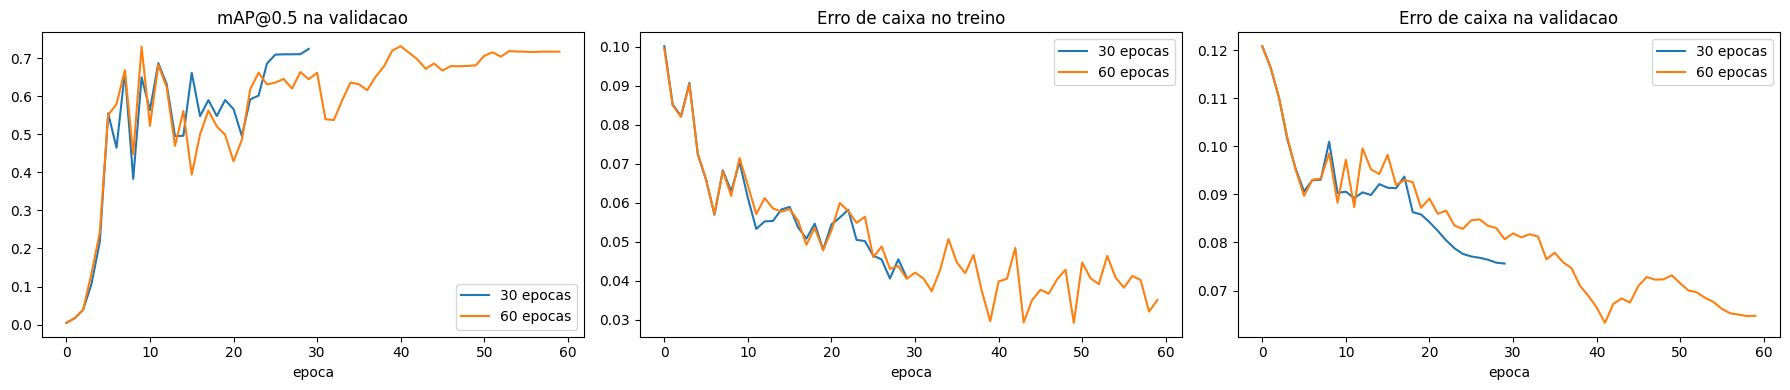

In [16]:
# evolucao das metricas ao longo das epocas
fig, eixos = plt.subplots(1, 3, figsize=(18, 4))

eixos[0].plot(res30['epoch'], res30['metrics/mAP_0.5'], label='30 epocas')
eixos[0].plot(res60['epoch'], res60['metrics/mAP_0.5'], label='60 epocas')
eixos[0].set_title('mAP@0.5 na validacao')
eixos[0].set_xlabel('epoca')
eixos[0].legend()

eixos[1].plot(res30['epoch'], res30['train/box_loss'], label='30 epocas')
eixos[1].plot(res60['epoch'], res60['train/box_loss'], label='60 epocas')
eixos[1].set_title('Erro de caixa no treino')
eixos[1].set_xlabel('epoca')
eixos[1].legend()

eixos[2].plot(res30['epoch'], res30['val/box_loss'], label='30 epocas')
eixos[2].plot(res60['epoch'], res60['val/box_loss'], label='60 epocas')
eixos[2].set_title('Erro de caixa na validacao')
eixos[2].set_xlabel('epoca')
eixos[2].legend()

plt.tight_layout()
plt.show()

In [17]:
# validacao dos melhores pesos (best.pt) com metricas por classe
!python val.py --weights runs/train/treino_30ep/weights/best.pt --data /content/dataset.yaml --img 640 --name val_30ep
!python val.py --weights runs/train/treino_60ep/weights/best.pt --data /content/dataset.yaml --img 640 --name val_60ep

val: data=/content/dataset.yaml, weights=['runs/train/treino_30ep/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=val_30ep, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.6it/s 0.6s
                   all          8         11      0.712      0.786      0.687      0.405
                  vaca          8          7       0.99      0.571      0.587      0.265
                trator          8          4      0.43

## 9. Teste

Avaliação dos dois modelos nas 8 imagens de teste (4 vacas e 4 tratores), que não foram usadas nem no treinamento nem na validação. Os resultados de cada execução ficam em `yolov5/runs/detect/`, conforme a mensagem *Results saved to runs/detect/...* exibida ao final do `detect.py`.

In [18]:
# deteccao nas imagens de teste com cada modelo (confianca minima de 25%)
inicio = time.time()
!python detect.py --weights runs/train/treino_30ep/weights/best.pt --source /content/dataset/teste --img 640 --conf 0.25 --name teste_30ep
tempo_det_30 = time.time() - inicio

inicio = time.time()
!python detect.py --weights runs/train/treino_60ep/weights/best.pt --source /content/dataset/teste --img 640 --conf 0.25 --name teste_60ep
tempo_det_60 = time.time() - inicio

print(f'Tempo total da deteccao (30 epocas): {tempo_det_30:.1f} s')
print(f'Tempo total da deteccao (60 epocas): {tempo_det_60:.1f} s')

detect: weights=['runs/train/treino_30ep/weights/best.pt'], source=/content/dataset/teste, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=teste_30ep, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/dataset/teste/trator_01_teste.jpg: 448x640 3 trators, 27.9ms
image 2/8 /content/dataset/teste/trator_02_teste.jpg: 448x640 2 trators, 12.3ms
image 3/8 /content/dataset/teste/trator_03_teste.jpg: 384x640 1 trator, 28.6ms
image 4/8 /content/dataset/teste/trator_04_teste.jpg: 448x640 2 trators,

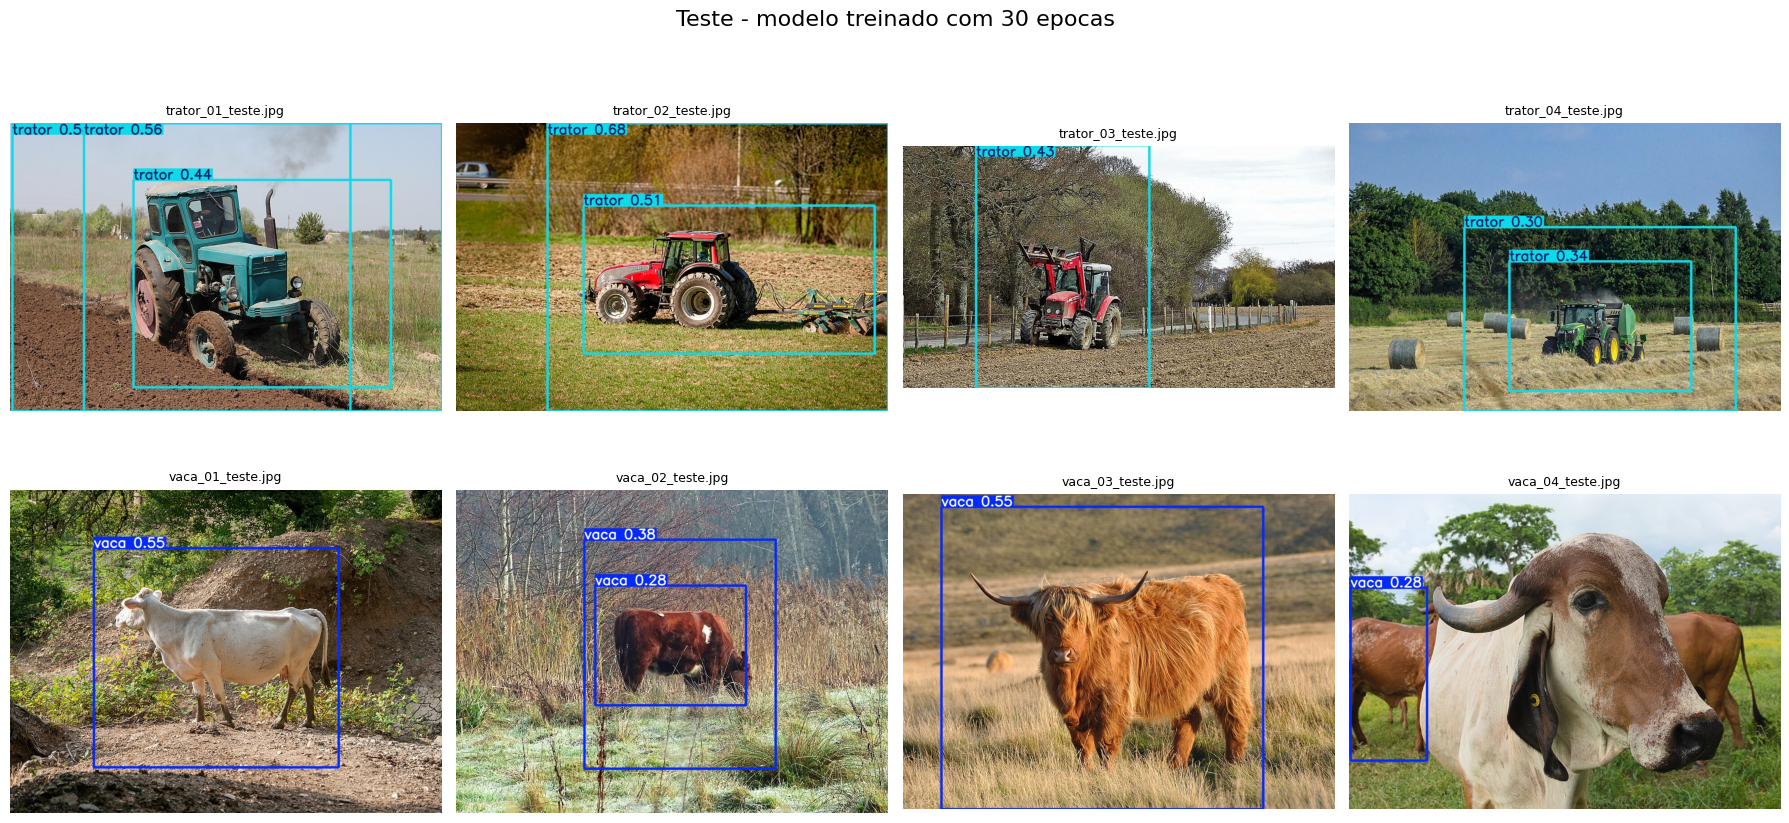

In [19]:
# exibe as imagens de teste processadas pelo modelo
def mostrar_resultados(pasta, titulo):
    arquivos = sorted(glob.glob(os.path.join(pasta, '*.jpg')))
    fig, eixos = plt.subplots(2, 4, figsize=(18, 9))
    for eixo, arq in zip(eixos.flatten(), arquivos):
        eixo.imshow(Image.open(arq))
        eixo.set_title(os.path.basename(arq), fontsize=9)
        eixo.axis('off')
    fig.suptitle(titulo, fontsize=16)
    plt.tight_layout()
    plt.show()

mostrar_resultados('runs/detect/teste_30ep', 'Teste - modelo treinado com 30 epocas')

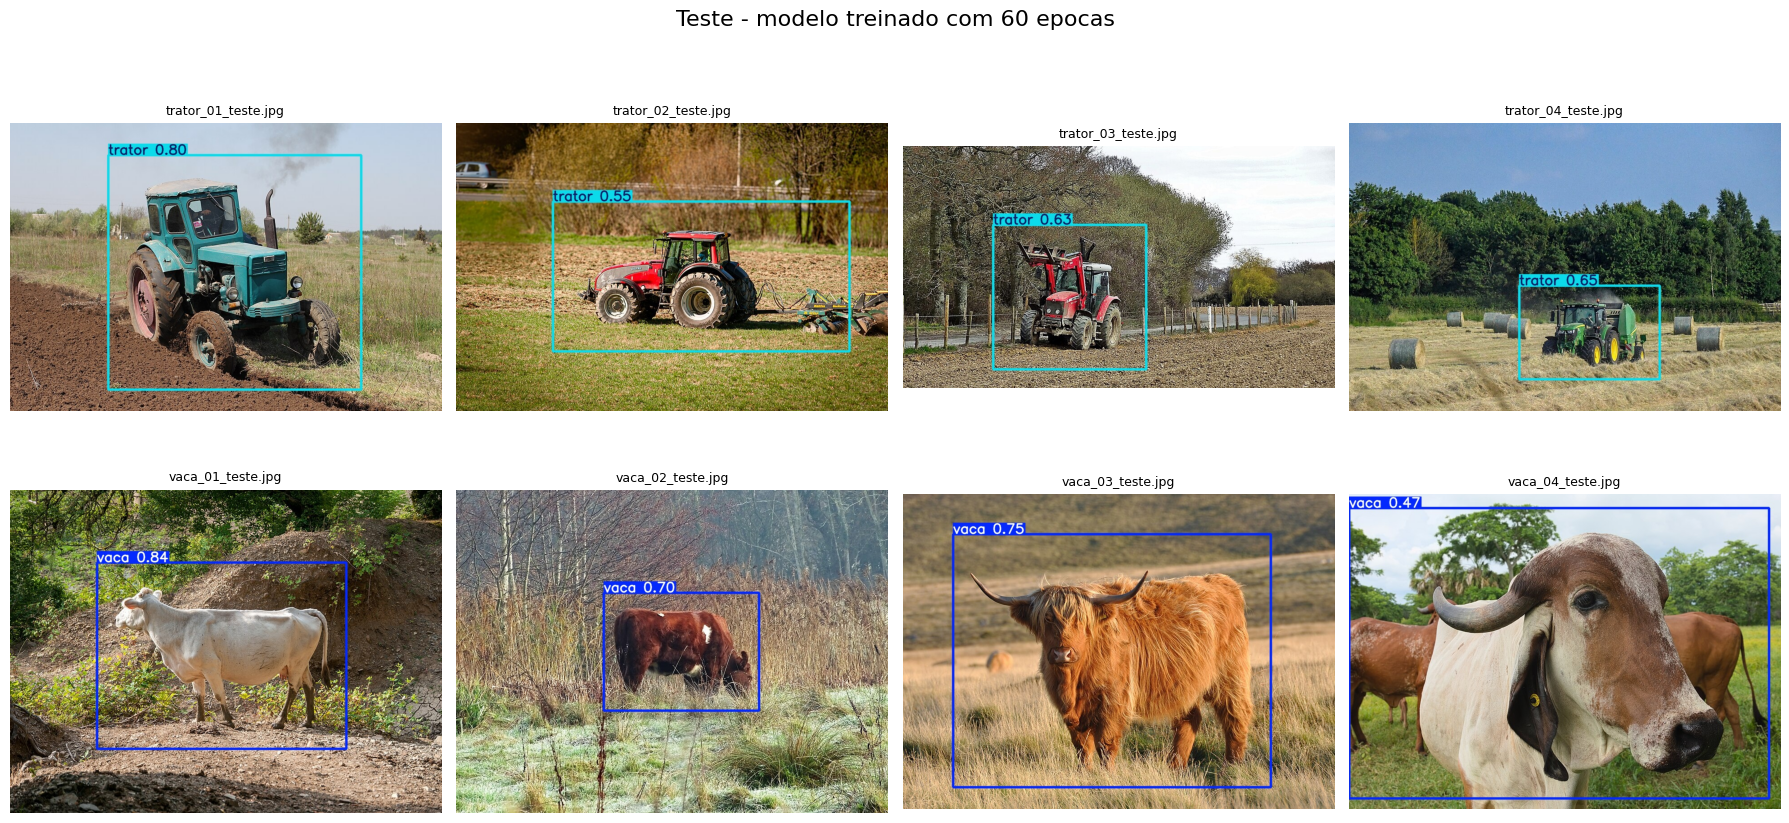

In [20]:
# resultado do modelo de 60 epocas
mostrar_resultados('runs/detect/teste_60ep', 'Teste - modelo treinado com 60 epocas')

In [21]:
# copia dos resultados para o Drive
destino = os.path.join(BASE, 'resultados')

if os.path.exists(destino):
    shutil.rmtree(destino)

shutil.copytree('runs', destino)
print('Resultados salvos em:', destino)

Resultados salvos em: /content/drive/MyDrive/FIAP/FASE6_CAP1/resultados


## 10. Conclusões

### Resultados da validação

**Valores da última época de cada treino:**

| Métrica | 30 épocas | 60 épocas |
|---|---|---|
| Precisão | 0,745 | 0,799 |
| Recall | 0,786 | 0,786 |
| mAP@0.5 | 0,725 | 0,717 |
| mAP@0.5:0.95 | 0,380 | 0,454 |
| Erro de caixa (val) | 0,076 | 0,065 |
| Tempo de treino | 2,9 min | 4,1 min |

**Melhores pesos (`best.pt`), avaliados pelo `val.py`:**

| Classe | Métrica | 30 épocas | 60 épocas |
|---|---|---|---|
| Geral | mAP@0.5 | 0,687 | 0,719 |
| Geral | mAP@0.5:0.95 | 0,405 | 0,503 |
| Vaca | Precisão / Recall | 0,990 / 0,571 | 0,787 / 0,571 |
| Trator | Precisão / Recall | 0,434 / 1,000 | 0,793 / 0,964 |

Os principais pontos observados foram:

- O **mAP@0.5** ficou praticamente igual nos dois treinos (entre 0,69 e 0,72). Ou seja, com 30 épocas o modelo já aprende a encontrar os objetos.
- O **mAP@0.5:0.95** subiu de 0,405 para 0,503 com 60 épocas. Como essa métrica exige caixas mais justas, o resultado indica que o treino mais longo melhorou a **precisão da localização**.
- A **precisão na classe trator** passou de 0,434 para 0,793. Com 30 épocas o modelo acertava todos os tratores, mas gerava várias caixas extras (falsos positivos). Com 60 épocas essas caixas duplicadas praticamente sumiram.
- O **recall da classe vaca** ficou em 0,571 nos dois casos. Uma das imagens de validação tem três vacas pequenas ao fundo, e o modelo não consegue detectar objetos tão pequenos com tão poucos exemplos desse tipo no treino.
- O **erro de caixa na validação** caiu de 0,076 para 0,065 e continuou diminuindo até o final, sem sinal claro de overfitting nas 60 épocas.

As pequenas diferenças entre a tabela da última época e o `val.py` acontecem porque o `best.pt` guarda a época com melhor desempenho geral, que nem sempre é a última.

### Resultados do teste

Nas 8 imagens de teste, nenhum dos dois modelos confundiu vaca com trator. A diferença ficou na qualidade das caixas:

- **30 épocas:** 13 detecções para 8 imagens. Houve caixas duplicadas ou muito grandes em `trator_01`, `trator_02`, `trator_04` e `vaca_02`. Em `vaca_04` o modelo marcou só uma vaca no canto da imagem e não detectou a vaca em primeiro plano. As confianças ficaram entre 0,28 e 0,68.
- **60 épocas:** exatamente uma detecção por imagem, todas na classe correta e com caixas bem ajustadas ao objeto. As confianças ficaram entre 0,47 e 0,84 (média de aproximadamente 0,67). A única limitação foi em `vaca_04`, onde as duas vacas ao fundo não foram detectadas.

O tempo de inferência foi praticamente o mesmo nos dois modelos (cerca de 18 ms por imagem na GPU T4), o que é esperado, já que a arquitetura é a mesma e só muda o número de épocas de treino.

### Aumentar as épocas valeu a pena?

Sim. Com cerca de 44% a mais de tempo de treino (de 2,9 para 4,1 minutos), o modelo de 60 épocas produziu caixas mais precisas, eliminou a maior parte dos falsos positivos e teve o melhor desempenho visual no teste. Como o tempo total ainda é baixo, o custo extra compensa. Mesmo assim, com apenas 8 imagens de validação e 8 de teste, cada acerto ou erro muda bastante as métricas, então as diferenças precisam ser vistas com cautela.

### Pontos fortes

- O YOLOv5 pré-treinado permitiu obter um modelo funcional com apenas 64 imagens de treino e poucos minutos de GPU
- Nenhuma confusão entre as classes vaca e trator, tanto na validação quanto no teste
- Inferência rápida (cerca de 18 ms por imagem), viável para aplicações em tempo real, como monitoramento por câmeras
- Processo simples de reproduzir: rotulação, treino e teste executados em um único notebook

### Limitações

- Dataset muito pequeno (80 imagens), o que reduz a confiabilidade estatística das métricas
- Dificuldade com objetos pequenos ou distantes, como vacas ao fundo da imagem
- O conjunto de teste não tem rótulos, então a avaliação do teste foi apenas visual
- Apenas o número de épocas foi variado; outros hiperparâmetros (tamanho do modelo, resolução, batch) não foram testados
- A rotulação manual pode ter pequenas imprecisões nas caixas

### Próximos passos

Para evoluir o sistema, seria importante aumentar o número de imagens, incluir mais fotos com vários objetos e objetos distantes, e testar versões maiores do modelo, como o `yolov5m`. Na Entrega 2, este modelo será comparado com a YOLO padrão e com uma CNN treinada do zero.